> **Bản PyTorch** của `examples/1. MLP/Func_apxm_MLP.ipynb` (Keras). Người chuyển: TV1 – Đoàn Trung Kiên.
>
> **Thay đổi so với bản Keras**

> - Bỏ `tensorflow.keras` (`Model`, `Input`, `Dense`, `SGD`); dùng `torch`, `torch.nn`, `TensorDataset`, `DataLoader` và chọn thiết bị `device` (`cuda` nếu có GPU).
> - `gauss_mlp(B)`: `Model(Input(2), Dense(B, 'sigmoid'), Dense(1, 'sigmoid'))` → lớp `GaussMLP(nn.Module)` gồm `nn.Linear(2, B)` + `Sigmoid` và `nn.Linear(B, 1)` + `Sigmoid`, `.squeeze(-1)` để đầu ra có shape `(N,)` khớp với nhãn `y`.
> - Khởi tạo trọng số bằng `init_like_keras` (`xavier_uniform_`, `bias = 0`) giống mặc định `glorot_uniform` của Keras.
> - Bài toán hồi quy xấp xỉ mặt Gaussian 2D: dùng `nn.MSELoss()` thay cho `'mean_squared_error'`, nhãn `y` để kiểu `torch.float32`.
> - Các hàm `summary`, `init_like_keras`, `train_one_epoch`, `evaluate`, `fit`, `predict`, `make_loader` chép từ khuôn `MNIST_MLP` vào trực tiếp trong notebook (điều chỉnh cho hồi quy MSE, không dùng file chung).

# (1) import libraries

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import multivariate_normal
from IPython.display import clear_output

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device,
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Chép từ khuôn `MNIST_MLP` và điều chỉnh cho bài toán hồi quy MSE (nhãn thực `float32`, không tính accuracy phân lớp). Mỗi notebook tự chứa các hàm này, không phụ thuộc file code ngoài.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense bằng glorot_uniform và bias = 0."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader cho bài toán hồi quy (x, y đều là float32)."""
    ds = TensorDataset(
        torch.tensor(np.asarray(x), dtype=torch.float32),
        torch.tensor(np.asarray(y), dtype=torch.float32),
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện hồi quy; trả về MSE trung bình trên tập train."""
    model.train()
    total_loss, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x)
        loss = loss_fn(pred, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        n += len(y)
    return total_loss / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(..., verbose=0): trả về loss trung bình trên tập."""
    model.eval()
    total_loss, n = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            total_loss += loss_fn(pred, y).item() * len(y)
            n += len(y)
    return total_loss / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs, verbose=0):
    """Tương đương model.fit(..., validation_data=..., verbose=0)."""
    history = {'loss': [], 'val_loss': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss = evaluate(model, val_loader, loss_fn)
        history['loss'].append(loss)
        history['val_loss'].append(val_loss)
        if verbose:
            print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.2f}s - loss: {loss:.6f} - val_loss: {val_loss:.6f}')
    return history


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về giá trị dự đoán hồi quy dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(model(xb).cpu().numpy())
    return np.concatenate(out)

# (2) data preparation

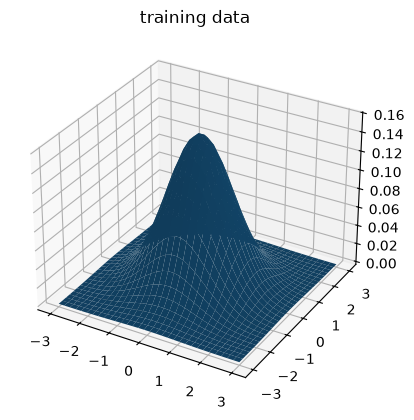

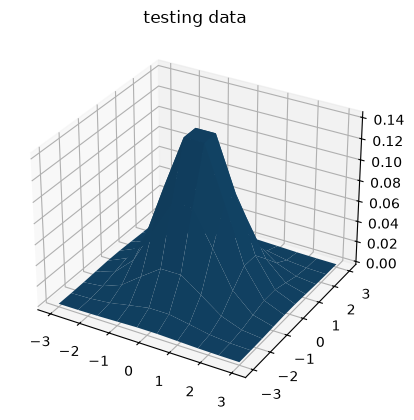

x_train: (1024, 2) y_train: (1024,)
x_test : (100, 2) y_test : (100,)


In [3]:
# training ------------------------------
A = 32j
x1, x2 = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2 = np.column_stack([x1.flat, x2.flat])

mu = np.array([0.0, 0.0])
covariance = np.diag([1, 1])

y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance)
y = y.reshape(x1.shape)

x_train = x1x2.astype('float32')
y_train = y.flatten().astype('float32')

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1, x2, y)
plt.title('training data')
plt.show()

# testing -------------------------------
A = 10j
x1, x2 = np.mgrid[-3.0:3.0:A, -3.0:3.0:A]
x1x2 = np.column_stack([x1.flat, x2.flat])

mu = np.array([0.0, 0.0])
covariance = np.diag([1, 1])

y = multivariate_normal.pdf(x1x2, mean=mu, cov=covariance)
y = y.reshape(x1.shape)

x_test = x1x2.astype('float32')
y_test = y.flatten().astype('float32')

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1, x2, y)
plt.title('testing data')
plt.show()

print('x_train:', x_train.shape, 'y_train:', y_train.shape)
print('x_test :', x_test.shape, 'y_test :', y_test.shape)

# (3) MLP

In [4]:
class GaussMLP(nn.Module):
    def __init__(self, B=16):
        super().__init__()
        self.fc = nn.Linear(2, B)                 # Dense(units=B, activation='sigmoid', name='fc')
        self.act1 = nn.Sigmoid()
        self.gauss_apxm = nn.Linear(B, 1)         # Dense(units=1, activation='sigmoid', name='gauss_apxm')
        self.act2 = nn.Sigmoid()

    def forward(self, x):
        x = self.act1(self.fc(x))
        return self.act2(self.gauss_apxm(x)).squeeze(-1)


def gauss_mlp(B=16):
    model = GaussMLP(B=B).to(device)
    init_like_keras(model)
    return model


summary(gauss_mlp(B=16), (2,))

Layer (type)                        Output Shape               Param #
fc (Linear)                         (None, 16)                      48
act1 (Sigmoid)                      (None, 16)                       0
gauss_apxm (Linear)                 (None, 1)                       17
act2 (Sigmoid)                      (None, 1)                        0
Total params: 65


# (4) training and evaluating MLP

### (4.1) Number of training samples (A) (no. of hidden nodes (B) = 16 and no. of epochs (C) = 100)

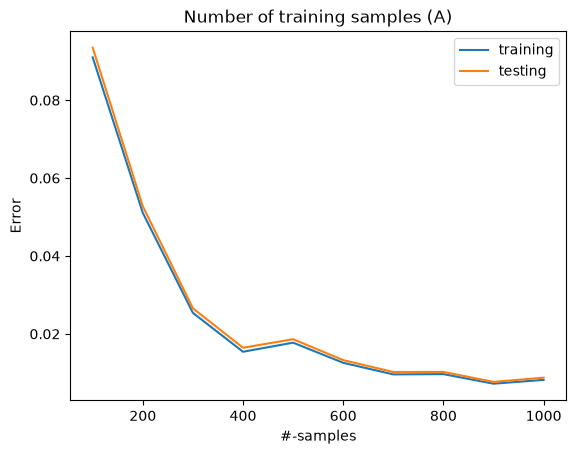

> Sweep (4.1) time: 11.41s (0.1901 min) | A=100 -> test MSE=0.093483 | A=1000 -> train MSE=0.008185, test MSE=0.008752


In [5]:
np.random.seed(SEED)
torch.manual_seed(SEED)

train_error = []
test_error = []
tot_train = 1001
A_array = []

B = 16
C = 100
batch_size = 128
lr = 0.01
loss_fn = nn.MSELoss()
full_train_loader = make_loader(x_train, y_train, batch_size=batch_size, shuffle=False)
test_loader = make_loader(x_test, y_test, batch_size=batch_size, shuffle=False)

t0 = time.time()
for A in np.arange(100, tot_train, 100):
    model = gauss_mlp(B=B)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    sel_indx = np.random.choice(range(1, tot_train), size=int(A), replace=False)
    sub_train_loader = make_loader(x_train[sel_indx], y_train[sel_indx], batch_size=batch_size, shuffle=True)
    fit(model, sub_train_loader, test_loader, loss_fn, optimizer, epochs=C, verbose=0)

    train_error.append(evaluate(model, full_train_loader, loss_fn))
    test_error.append(evaluate(model, test_loader, loss_fn))
    A_array.append(int(A))

    clear_output(wait=True)
    plt.plot(A_array, train_error, label='training')
    plt.plot(A_array, test_error, label='testing')
    plt.legend()
    plt.title('Number of training samples (A)')
    plt.xlabel('#-samples')
    plt.ylabel('Error')
    plt.show()

elapsed_A = time.time() - t0
print(f'> Sweep (4.1) time: {elapsed_A:.2f}s ({elapsed_A / 60:.4f} min) | '
      f'A={A_array[0]} -> test MSE={test_error[0]:.6f} | A={A_array[-1]} -> train MSE={train_error[-1]:.6f}, test MSE={test_error[-1]:.6f}')

### (4.2) Number of hidden nodes (B) (no. of training samples (A) = 800 and no. of epochs (C) = 100)

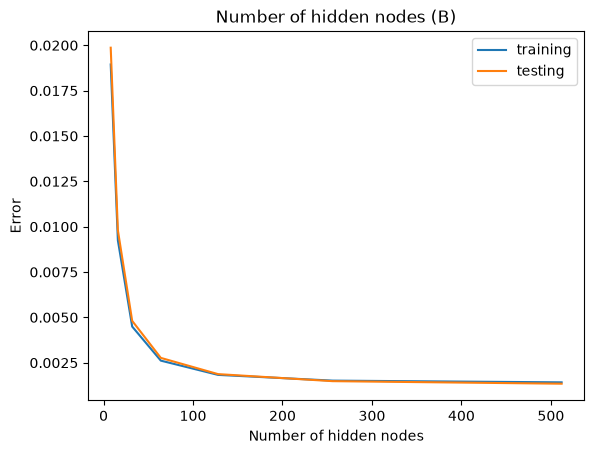

> Sweep (4.2) time: 9.65s (0.1608 min) | B=8 -> test MSE=0.019867 | B=512 -> train MSE=0.001419, test MSE=0.001344


In [6]:
np.random.seed(SEED)
torch.manual_seed(SEED)

train_error = []
test_error = []
B_array = []
tot_train = 1001

A = 800
B = 8
C = 100
batch_size = 128
lr = 0.01
loss_fn = nn.MSELoss()

t0 = time.time()
while B <= 512:
    model = gauss_mlp(B=B)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)
    sub_train_loader = make_loader(x_train[sel_indx], y_train[sel_indx], batch_size=batch_size, shuffle=True)
    fit(model, sub_train_loader, test_loader, loss_fn, optimizer, epochs=C, verbose=0)

    train_error.append(evaluate(model, full_train_loader, loss_fn))
    test_error.append(evaluate(model, test_loader, loss_fn))
    B_array.append(B)

    clear_output(wait=True)
    plt.plot(B_array, train_error, label='training')
    plt.plot(B_array, test_error, label='testing')
    plt.legend()
    plt.title('Number of hidden nodes (B)')
    plt.xlabel('Number of hidden nodes')
    plt.ylabel('Error')
    plt.show()

    B *= 2

elapsed_B = time.time() - t0
print(f'> Sweep (4.2) time: {elapsed_B:.2f}s ({elapsed_B / 60:.4f} min) | '
      f'B={B_array[0]} -> test MSE={test_error[0]:.6f} | B={B_array[-1]} -> train MSE={train_error[-1]:.6f}, test MSE={test_error[-1]:.6f}')

### (4.3) Number of epochs (C) (no. of training samples (A) = 800 and no. of hidden nodes (B) = 128)

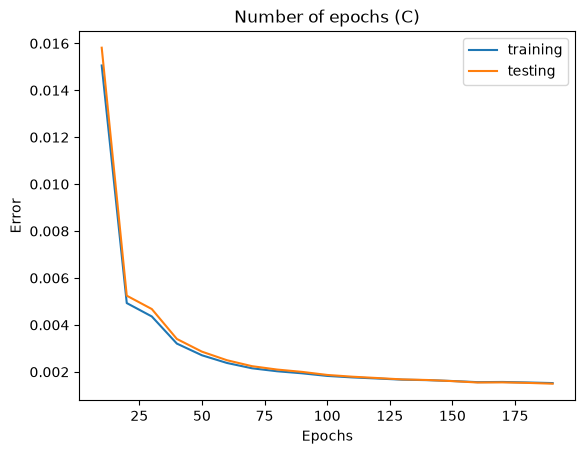

> Sweep (4.3) time: 25.64s (0.4273 min) | C=10 -> test MSE=0.015815 | C=190 -> train MSE=0.001521, test MSE=0.001494
> Total training & evaluation time (4.1 + 4.2 + 4.3): 46.69s (0.7781 minutes)


In [7]:
np.random.seed(SEED)
torch.manual_seed(SEED)

train_error = []
test_error = []
tot_train = 1001
C_array = []

A = 800
B = 128
batch_size = 128
lr = 0.01
loss_fn = nn.MSELoss()

t0 = time.time()
for C in np.arange(10, 200, 10):
    model = gauss_mlp(B=B)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    sel_indx = np.random.choice(range(1, tot_train), size=A, replace=False)
    sub_train_loader = make_loader(x_train[sel_indx], y_train[sel_indx], batch_size=batch_size, shuffle=True)
    fit(model, sub_train_loader, test_loader, loss_fn, optimizer, epochs=int(C), verbose=0)

    train_error.append(evaluate(model, full_train_loader, loss_fn))
    test_error.append(evaluate(model, test_loader, loss_fn))
    C_array.append(int(C))

    clear_output(wait=True)
    plt.plot(C_array, train_error, label='training')
    plt.plot(C_array, test_error, label='testing')
    plt.legend()
    plt.title('Number of epochs (C)')
    plt.xlabel('Epochs')
    plt.ylabel('Error')
    plt.show()

elapsed_C = time.time() - t0
tot_time = elapsed_A + elapsed_B + elapsed_C
print(f'> Sweep (4.3) time: {elapsed_C:.2f}s ({elapsed_C / 60:.4f} min) | '
      f'C={C_array[0]} -> test MSE={test_error[0]:.6f} | C={C_array[-1]} -> train MSE={train_error[-1]:.6f}, test MSE={test_error[-1]:.6f}')
print(f'> Total training & evaluation time (4.1 + 4.2 + 4.3): {tot_time:.2f}s ({tot_time / 60:.4f} minutes)')